# 01 — Quickstart: make a mock web and score a filament finder

`gtweb` builds a mock cosmic web whose filaments and nodes are **known exactly**, realised as a
dark-matter-like particle field. You run your filament finder on the particles and compare what it
finds with the true network.

This notebook:
1. generates a small mock (50 Mpc/h box, 64³ particles, about a minute on a laptop);
2. looks at what was written;
3. plots the particles with the true filaments on top;
4. scores a simple example finder against the truth, overall and filament by filament.

Notebook 02 shows how the mock is built step by step; notebook 03 shows how to score your own finder
(including a worked DisPerSE example).

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

try:
    import gtweb
except ImportError:                       # running from a clone without `pip install -e .`
    sys.path.insert(0, str(Path.cwd().parent))
    import gtweb

plt.style.use(Path(gtweb.__file__).parent / "gtweb.mplstyle")
print("gtweb", gtweb.__version__)

gtweb 1.0.0


## 1. Generate a mock

`generate_mock` draws a Gaussian random field with the linear ΛCDM power spectrum (Planck cosmology),
grows it to z = 0 and builds the mock from it. Everything is deterministic for a given `seed`.

The paper's mock used `box=100, ngrid=384` (56.6 million particles). Here we use a small box so the
notebook runs quickly. The construction settings (void barrier, smoothing scales, collapse amplitude,
halo model, diffuse fraction) default to the paper's values and are set in Mpc/h, so a smaller box is
the same construction, only with fewer voids.

In [2]:
OUT = Path("mock_quickstart")
meta = gtweb.generate_mock(OUT, box=50.0, ngrid=64, seed=1)
{k: meta[k] for k in ("n_voids", "n_nodes", "n_filaments", "n_halos", "n_particles")}

[gtweb] 262,144 particles, box 50 Mpc/h, IC density grid 64^3
[gtweb] void nuclei + Laguerre weight fit ...
    it    0  mean|dV|/V  3.187  empty    0  lr 0.600
    it   20  mean|dV|/V  0.442  empty    2  lr 0.450
    it   40  mean|dV|/V  0.020  empty    0  lr 0.360
    it   60  mean|dV|/V  0.010  empty    0  lr 0.300
    it   80  mean|dV|/V  0.010  empty    0  lr 0.257
    it  100  mean|dV|/V  0.009  empty    0  lr 0.225
    it  120  mean|dV|/V  0.009  empty    0  lr 0.200
    it  140  mean|dV|/V  0.010  empty    0  lr 0.180
    it  160  mean|dV|/V  0.007  empty    0  lr 0.164
    it  180  mean|dV|/V  0.008  empty    0  lr 0.150
    it  200  mean|dV|/V  0.009  empty    0  lr 0.138
    it  220  mean|dV|/V  0.009  empty    0  lr 0.129
    it  240  mean|dV|/V  0.010  empty    0  lr 0.120
    it  259  mean|dV|/V  0.011  empty    0  lr 0.113
        69 voids, radii P10/50/90 [2.1  3.22 5.74] Mpc/h  [35s]
[gtweb] closed-form skeleton ...
        430 nodes, 854 filaments  [36s]
[gtweb] colla

{'n_voids': 69,
 'n_nodes': 430,
 'n_filaments': 854,
 'n_halos': 1055,
 'n_particles': 262144}

## 2. What was written

| file | contents |
|---|---|
| `mock_particles_s1.npz` | `positions` (N,3) Mpc/h, `stage` (0 void, 1 wall, 2 filament, 3 node, before the diffuse mix), `velocities` (N,3) km/s |
| `ground_truth_spines.npz` | the true filaments: one straight spine per filament (`spine_i`, wrapped into the box), `filament_lengths`, `filament_target_contrast` (mean density along the spine, ρ/ρ̄), `node_positions` |
| `nodes_catalogue.npz` | the true nodes and `peaks`, the particle mass within 1.5 Mpc/h of each node |
| `halos_catalogue.npz` | the mock's haloes (positions, masses): a discrete tracer of the same web |
| `web_geometry.npz` | the tessellation itself (nuclei, weights, void radii) |
| `velocity_field.npz` | a 2LPT velocity cube |
| `metadata.json` | every setting used |

Spines are stored wrapped into the periodic box; use the minimum-image convention before
differencing consecutive points.

In [3]:
gt = gtweb.load_ground_truth(OUT / "ground_truth_spines.npz")
nodes = gtweb.load_nodes(OUT / "nodes_catalogue.npz")
parts = gtweb.load_particles(OUT / "mock_particles_s1.npz")
halos = gtweb.load_halos(OUT / "halos_catalogue.npz")

box = float(gt["box_size"])
spines = gt["spines"]
L = np.asarray(gt["filament_lengths"])
contrast = np.asarray(gt["filament_target_contrast"])
pos = np.asarray(parts["positions"], float)

print(f"box {box:g} Mpc/h, {len(pos):,} particles")
print(f"{len(spines)} filaments: length median {np.median(L):.2f} Mpc/h, max {L.max():.1f}")
print(f"filament contrast (rho/mean along the spine): P10/50/90 = {np.percentile(contrast, [10, 50, 90]).round(1)}")
print(f"{len(nodes['positions'])} nodes, {len(halos['positions'])} haloes "
      f"(M = {halos['mass'].min():.1e} to {halos['mass'].max():.1e} Msun/h)")

box 50 Mpc/h, 262,144 particles
854 filaments: length median 4.08 Mpc/h, max 20.7
filament contrast (rho/mean along the spine): P10/50/90 = [ 7.  20.5 64.1]
430 nodes, 1055 haloes (M = 8.1e+11 to 1.6e+14 Msun/h)


## 3. The particles and the true web

A 6 Mpc/h thick slab of the particle field, with the true filament spines (orange) and nodes (green)
that cross the slab.

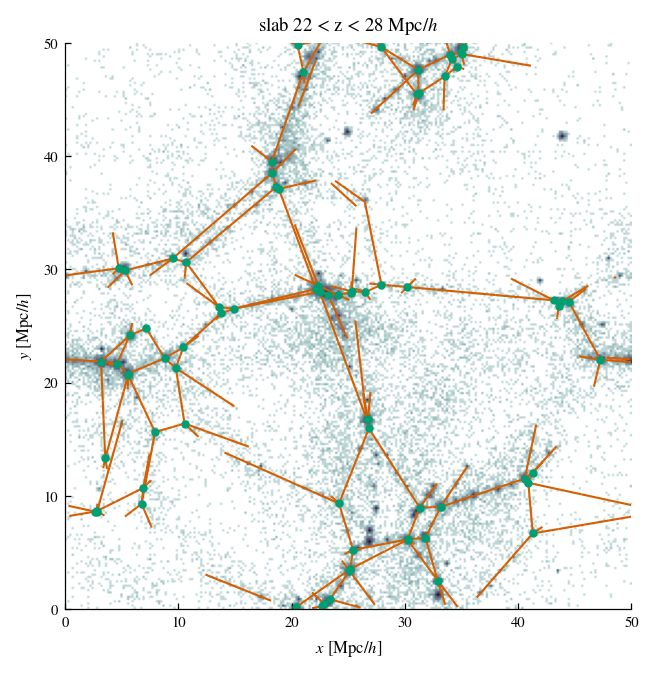

In [4]:
def spine_segments_in_slab(spines, box, zc, dz):
    """Pieces of the (wrapped) spines inside the slab |z - zc| < dz, as 2D segments for plotting."""
    segs = []
    for s in spines:
        p = np.asarray(s, float)
        d = np.diff(p, axis=0); d -= box * np.round(d / box)          # spines are stored wrapped
        p0 = p[:-1] % box
        for a, step in zip(p0, d):
            b = a + step
            za, zb = a[2], b[2]
            lo, hi = zc - dz, zc + dz
            if max(za, zb) < lo or min(za, zb) > hi:
                continue
            t0, t1 = 0.0, 1.0
            if zb != za:                                                  # clip the segment to the slab
                ta, tb = (lo - za) / (zb - za), (hi - za) / (zb - za)
                t0, t1 = max(0.0, min(ta, tb)), min(1.0, max(ta, tb))
            if t1 > t0:
                segs.append([(a + t0 * step)[:2], (a + t1 * step)[:2]])
    return segs


def slab_image(pos, box, zc, dz, bins=256):
    sub = pos[np.abs(pos[:, 2] - zc) < dz]
    H, _, _ = np.histogram2d(sub[:, 0], sub[:, 1], bins=bins, range=[[0, box], [0, box]])
    return np.log10(1.0 + H / max(H.mean(), 1e-12)).T


from matplotlib.collections import LineCollection

zc, dz = box / 2, 3.0
fig, ax = plt.subplots(figsize=(5.0, 5.0))
ax.imshow(slab_image(pos, box, zc, dz), origin="lower", extent=[0, box, 0, box], cmap="bone_r")
ax.add_collection(LineCollection(spine_segments_in_slab(spines, box, zc, dz), colors="#D55E00", lw=1.0))
nn = nodes["positions"][np.abs(nodes["positions"][:, 2] - zc) < dz]
ax.plot(nn[:, 0], nn[:, 1], "o", ms=3, color="#009E73")
ax.set(xlim=(0, box), ylim=(0, box), xlabel=r"$x$ [Mpc/$h$]", ylabel=r"$y$ [Mpc/$h$]",
       title=f"slab {zc - dz:g} < z < {zc + dz:g} Mpc/$h$")
plt.show()

## 4. Score a finder

As a stand-in for a real finder we build a deliberately simple one: the **minimum spanning tree of
the haloes** above a mass cut, keeping edges shorter than 6 Mpc/h. Each MST edge is a straight
"filament". Replace this block with your own finder's output: a list of (M,3) polylines, or an (N,3)
cloud of points sampled along your skeleton.

`score_finder` resamples both networks every 0.3 Mpc/h and reports

* **completeness**: the fraction of the true network within `tol` of your skeleton;
* **purity**: the fraction of your skeleton within `tol` of the true network.

In [5]:
from scipy.spatial import cKDTree
from scipy.sparse.csgraph import minimum_spanning_tree


def halo_mst_finder(halo_pos, box, max_edge=6.0):
    tree = cKDTree(halo_pos, boxsize=box)
    G = tree.sparse_distance_matrix(tree, max_edge).tocsr()
    T = minimum_spanning_tree(G).tocoo()
    skel = []
    for i, j in zip(T.row, T.col):
        a = halo_pos[i]; d = halo_pos[j] - a; d -= box * np.round(d / box)
        skel.append(np.array([a, a + d]) % box)
    return skel


hp, hm = halos["positions"], halos["mass"]
finder = halo_mst_finder(hp[hm > np.percentile(hm, 50)], box)
print(f"example finder: {len(finder)} MST edges")
for tol in (1.0, 2.0):
    s = gtweb.score_finder(finder, spines, box, tol=tol)
    print(f"tol {tol:.1f} Mpc/h: completeness {s['completeness']:.3f}, purity {s['purity']:.3f}")

example finder: 508 MST edges
tol 1.0 Mpc/h: completeness 0.504, purity 0.899
tol 2.0 Mpc/h: completeness 0.679, purity 0.966


## 5. Which filaments are missed?

Because every true filament is known, completeness can be measured filament by filament and binned
by any property of the truth. Here: by the filament's density contrast and by its length.

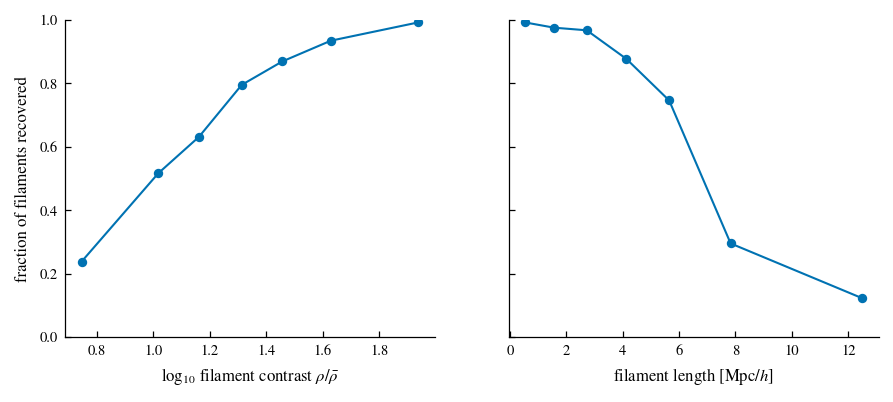

In [6]:
per_fil = gtweb.score_per_filament(finder, spines, box, tol=1.5)   # completeness of each true filament
found = per_fil > 0.5


def binned(x, y, nb=7):
    e = np.quantile(x, np.linspace(0, 1, nb + 1))
    i = np.clip(np.digitize(x, e[1:-1]), 0, nb - 1)
    return np.array([x[i == b].mean() for b in range(nb)]), np.array([y[i == b].mean() for b in range(nb)])


fig, axs = plt.subplots(1, 2, figsize=(7.0, 2.8), sharey=True)
for ax, x, lab in ((axs[0], np.log10(contrast), r"$\log_{10}$ filament contrast $\rho/\bar\rho$"),
                   (axs[1], L, r"filament length [Mpc/$h$]")):
    xc, yc = binned(x, found.astype(float))
    ax.plot(xc, yc, "o-")
    ax.set_xlabel(lab)
axs[0].set_ylabel("fraction of filaments recovered")
axs[0].set_ylim(0, 1)
plt.show()

The halo tree recovers the dense filaments and misses the faint ones, as a sparse tracer must.

**Next:** `02_how_the_mock_is_built.ipynb` walks through the construction;
`03_score_your_finder.ipynb` runs DisPerSE on the mock and calibrates its threshold against the
true nodes.